# Tutorial Básico de NumPy, Pandas y Matplotlib

 Estas tres librería son la base del ecosistema de estadística, ciencia de datos y programación científica en python. Este tutorial los puede ayudar a comprender los conceptos básicos detrás de estas herramientas, pero queda en sus manos explorar y estudiar nuevas herramientas que les puedan ser útiles para el curso y para su desarrollo como profesionales. El lugar ideal para hacerlo son las documentaciones oficiales de cada una de ellas.
- [Documentación de NumPy](https://numpy.org/doc/)
- [Documentación de Pandas](https://pandas.pydata.org/docs/)
- [Documentación de Matplotlib](https://matplotlib.org/stable/)

Los *llms*, como ChatGPT, Gemini o Claude, hoy en día comprenden de manera cada vez mejor estas librerías, por lo que pueden ser herramientas muy útiles para estudiarlas, resolver problemas y aprender nuevas técnicas. Siempre y cuando se utilicen de manera controlada.

Existen otras librerías que también pueden ser útiles en el contexto de la estadística, ciencia de datos y programación científica. Queda a su elección explorarlas y determinar si alguna de ellas puede ser útil para sus necesidades. Aquí algunas de ellas.
- [Scipy](https://scipy.org/): Librería para cálculos científicos y matemáticos generales. Esta librerías es muy amplia y puede ser útil para resolver varios problemas de análisis numérico.
- [Seaborn](https://seaborn.pydata.org/): Librería gráfica como Matplotlib. 
- [Plotly](https://plotly.com/python/): Librería gráfica pensada para gráficos interactivos. Muy útil al momento de hacer exploración de datos.
- [Polars](https://pola.rs/): Librería de manipulación y análisis de datos, similar a Pandas, pero con un rendimiento más alto y pensado para manejar grandes conjuntos de datos.

---
## 1. NumPy
NumPy es esencial para operaciones numéricas y nos permite usar *arrays* (estructura de datos multidimensionales) que son mucho más eficientes en memoria que las listas estándar de Python.

In [17]:
# importar la libería
import numpy as np

arr_1d = np.array([1, 2, 3, 4])
print("1D Array:\n", arr_1d)

arr_2d = np.array([[1, 2, 3], [4, 5, 6]])
print("\n2D Array:\n", arr_2d)

arr_3d = np.array([[[1, 2, 3], [4, 5, 6]], [[7, 8, 9], [10, 11, 12]]])
print("\n3D Array:\n", arr_3d)

1D Array:
 [1 2 3 4]

2D Array:
 [[1 2 3]
 [4 5 6]]

3D Array:
 [[[ 1  2  3]
  [ 4  5  6]]

 [[ 7  8  9]
  [10 11 12]]]


### 1.1 Crear arrays y mirar sus atributos

Rara vez escribimos los arrays a mano: NumPy tiene constructores para los casos frecuentes.
Todo array tiene una forma (`shape`) y un único tipo de dato (`dtype`) para todos
sus elementos.

In [18]:
print("np.arange(0, 10, 2):", np.arange(0, 10, 2))
print("np.linspace(0, 1, 5):", np.linspace(0, 1, 5))
print("np.zeros(3):", np.zeros(3))
print("np.ones(3):", np.ones(3))
print("np.ones((2, 3)):\n", np.ones((2, 3)))
print("np.ones((2,3,4)):\n", np.ones((2, 3, 4)))

print("\nshape:", arr_2d.shape, "| ndim:", arr_2d.ndim, "| size:", arr_2d.size, "| dtype:", arr_2d.dtype, "| sum:", arr_2d.sum())

np.arange(0, 10, 2): [0 2 4 6 8]
np.linspace(0, 1, 5): [0.   0.25 0.5  0.75 1.  ]
np.zeros(3): [0. 0. 0.]
np.ones(3): [1. 1. 1.]
np.ones((2, 3)):
 [[1. 1. 1.]
 [1. 1. 1.]]
np.ones((2,3,4)):
 [[[1. 1. 1. 1.]
  [1. 1. 1. 1.]
  [1. 1. 1. 1.]]

 [[1. 1. 1. 1.]
  [1. 1. 1. 1.]
  [1. 1. 1. 1.]]]

shape: (2, 3) | ndim: 2 | size: 6 | dtype: int64 | sum: 21


### 1.2 Indexación, *slicing* y filtros

La sintaxis es `array[filas, columnas]`, con `inicio:fin` (el `fin` **no** se incluye)
y `:` para "todo". Lo más útil de todo: las máscaras booleanas, que permiten
filtrar según una condición sin escribir ningún `for`.

In [19]:
print("np.arange(1,13):", np.arange(1,13))
M = np.arange(1, 13).reshape(3, 4)     # reshape: reorganiza los datos en 3 filas y 4 columnas
print("M =\n", M)
print("\nM[0, 2] (fila 0, col 2):", M[0, 2])
print("M[:, 1] (columna 1):", M[:, 1])
print("M[0:2, 1:3] (submatriz):\n", M[0:2, 1:3])

np.arange(1,13): [ 1  2  3  4  5  6  7  8  9 10 11 12]
M =
 [[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]

M[0, 2] (fila 0, col 2): 3
M[:, 1] (columna 1): [ 2  6 10]
M[0:2, 1:3] (submatriz):
 [[2 3]
 [6 7]]


In [20]:
x = np.array([12, 7, 3, 20, 15, 8])

print("Máscara x > 10 ", x > 10) # array de booleanos
print("x[x > 10]:", x[x > 10]) # nos quedamos solo con esos elementos
print("Cuántos son > 10:", (x > 10).sum())  
print("Elementos entre 5 y 15:", x[(x >= 5) & (x <= 15)]) # Condición compuesta con & (and) y | (or)

Máscara x > 10  [ True False False  True  True False]
x[x > 10]: [12 20 15]
Cuántos son > 10: 3
Elementos entre 5 y 15: [12  7 15  8]


### 1.3 Operaciones vectorizadas

Las operaciones se aplican elemento a elemento sobre todo el array, sin ciclos.
Esto se llama vectorizar: es más corto, más legible y mucho más rápido.
Si las formas no calzan, NumPy "estira" el array más chico.

In [21]:
a = np.array([1., 2., 3., 4.])
b = np.array([10., 20., 30., 40.])

print("a + b:", a + b)
print("a * b:", a * b) 
print("a ** 2:", a ** 2)
print("np.sqrt(a):", np.sqrt(a).round(3))
print("np.log(a):", np.log(a).round(2))
print("np.exp(a):", np.exp(a).round(1))
print("\nb + 100:", b + 100)

a + b: [11. 22. 33. 44.]
a * b: [ 10.  40.  90. 160.]
a ** 2: [ 1.  4.  9. 16.]
np.sqrt(a): [1.    1.414 1.732 2.   ]
np.log(a): [0.   0.69 1.1  1.39]
np.exp(a): [ 2.7  7.4 20.1 54.6]

b + 100: [110. 120. 130. 140.]


### 1.4 Estadísticos y el argumento `axis`

`axis=0` opera por columna y `axis=1` por fila. Sin `axis`, se usa todo el array.

In [22]:
notas = np.array([[4.5, 6.0, 5.5],      # cada fila = un estudiante
                  [3.0, 4.0, 5.0],      # cada columna = una prueba
                  [7.0, 6.5, 6.0]])

print("Promedio general:", notas.mean().round(2))
print("Mediana general:", np.median(notas))  
print("Promedio por prueba:", notas.mean(axis=0).round(2))   # una por columna
print("Mediana por prueba:", np.median(notas, axis=0))   # una por fila
print("Promedio por estudiante:", notas.mean(axis=1).round(2))   # una por fila
print("Máximo:", notas.max(), "| Mínimo:", notas.min())

Promedio general: 5.28
Mediana general: 5.5
Promedio por prueba: [4.83 5.5  5.5 ]
Mediana por prueba: [4.5 6.  5.5]
Promedio por estudiante: [5.33 4.   6.5 ]
Máximo: 7.0 | Mínimo: 3.0


In [23]:
y = np.array([2., 4., 4., 4., 5., 5., 7., 9.])

print("Media:", y.mean())
print("Mediana:", np.median(y))

Media: 5.0
Mediana: 4.5


---
## 2. Pandas

Pandas está construido sobre NumPy y agrega estructuras pensadas para **datos tabulares**
(como una planilla de cálculo excel):

- **`Series`**: una columna de datos con un índice.
- **`DataFrame`**: una tabla, o sea varias `Series` que comparten el mismo índice.

La diferencia con NumPy es que acá las columnas tienen nombre y pueden ser de
tipos distintos entre sí (números, texto, fechas).

In [24]:
import pandas as pd

df = pd.DataFrame({
    "estudiante": ["Ana", "Beto", "Carla", "Diego", "Elena", "Fran", "Gabi", "Hugo"],
    "carrera":    ["Ing.", "Ing.", "Ciencias", "Ciencias", "Ing.", "Ciencias", "Ing.", "Ciencias"],
    "edad":       [19, 21, 20, 22, 19, 23, 20, 21],
    "prueba_1":   [4.5, 6.0, 3.2, 7.0, 5.5, 6.8, 4.0, 5.9],
    "prueba_2":   [5.0, 5.5, 4.1, 6.5, 6.0, 6.2, 4.8, np.nan],   
})
df

,estudiante,carrera,edad,prueba_1,prueba_2
0,Ana,Ing.,19,4.5,5.0
1,Beto,Ing.,21,6.0,5.5
2,Carla,Ciencias,20,3.2,4.1
3,Diego,Ciencias,22,7.0,6.5
4,Elena,Ing.,19,5.5,6.0
5,Fran,Ciencias,23,6.8,6.2
6,Gabi,Ing.,20,4.0,4.8
7,Hugo,Ciencias,21,5.9,NaN


### 2.1 Leer archivos y explorar

En la práctica los datos vienen de un archivo: `pd.read_csv` es la función que más van
a usar. Al recibir datos nuevos, lo primero es mirar su forma, sus tipos y un resumen.

In [25]:
df.to_csv("results/notas.csv", index=False)  
df = pd.read_csv("results/notas.csv")          

print("Forma (filas, columnas):", df.shape)
print("Columnas:", list(df.columns))
df.head(3)                             

Forma (filas, columnas): (8, 5)
Columnas: ['estudiante', 'carrera', 'edad', 'prueba_1', 'prueba_2']


,estudiante,carrera,edad,prueba_1,prueba_2
0,Ana,Ing.,19,4.5,5.0
1,Beto,Ing.,21,6.0,5.5
2,Carla,Ciencias,20,3.2,4.1


In [26]:
df.describe()  

,edad,prueba_1,prueba_2
count,8.000000,8.000000,7.000000
mean,20.625000,5.362500,5.442857
std,1.407886,1.349008,0.858015
min,19.000000,3.200000,4.100000
25%,19.750000,4.375000,4.900000
50%,20.500000,5.700000,5.500000
75%,21.250000,6.200000,6.100000
max,23.000000,7.000000,6.500000


### 2.2 Seleccionar y filtrar

| Qué quiero | Cómo |
|---|---|
| Una columna (`Series`) | `df["col"]` |
| Varias columnas (`DataFrame`) | `df[["col1", "col2"]]` |
| Por **etiqueta** de fila/columna | `df.loc[filas, columnas]` |
| Por **posición** | `df.iloc[filas, columnas]` |
| Filtrar filas | `df[condición]` |

In [27]:
print("Una columna:")
print(df["prueba_1"].head(3))

print("\nVarias columnas:")
print(df[["estudiante", "prueba_1"]].head(3))

print("\ndf.loc[0:2, ['estudiante', 'edad']]:")
print(df.loc[0:2, ["estudiante", "edad"]])

print("\ndf.iloc[0:2, 0:2]:")
print(df.iloc[0:2, 0:2])

print("\nFiltro: prueba_1 >= 5.5")
print(df[df["prueba_1"] >= 5.5])

print("\nFiltro combinado: de Ingeniería y menores de 21")
print(df[(df["carrera"] == "Ing.") & (df["edad"] < 21)])

Una columna:
0    4.5
1    6.0
2    3.2
Name: prueba_1, dtype: float64

Varias columnas:
  estudiante  prueba_1
0        Ana       4.5
1       Beto       6.0
2      Carla       3.2

df.loc[0:2, ['estudiante', 'edad']]:
  estudiante  edad
0        Ana    19
1       Beto    21
2      Carla    20

df.iloc[0:2, 0:2]:
  estudiante carrera
0        Ana    Ing.
1       Beto    Ing.

Filtro: prueba_1 >= 5.5
  estudiante   carrera  edad  prueba_1  prueba_2
1       Beto      Ing.    21       6.0       5.5
3      Diego  Ciencias    22       7.0       6.5
4      Elena      Ing.    19       5.5       6.0
5       Fran  Ciencias    23       6.8       6.2
7       Hugo  Ciencias    21       5.9       NaN

Filtro combinado: de Ingeniería y menores de 21
  estudiante carrera  edad  prueba_1  prueba_2
0        Ana    Ing.    19       4.5       5.0
4      Elena    Ing.    19       5.5       6.0
6       Gabi    Ing.    20       4.0       4.8


### 2.3 Columnas nuevas y datos faltantes

`NaN` ("*not a number*") marca un dato ausente. Casi todas las funciones de pandas lo
ignoran al calcular, a diferencia de NumPy, donde contamina el resultado.

In [28]:
df["promedio"] = (df["prueba_1"] + df["prueba_2"]) / 2    # operación vectorizada
df["aprobado"] = df["promedio"] >= 4.0                    # columna booleana

print("Faltantes por columna:")
print(df.isna().sum())
print("\nMedia de prueba_2 (ignora el NaN):", df["prueba_2"].mean().round(3))
df.head(3)

Faltantes por columna:
estudiante    0
carrera       0
edad          0
prueba_1      0
prueba_2      1
promedio      1
aprobado      0
dtype: int64

Media de prueba_2 (ignora el NaN): 5.443


,estudiante,carrera,edad,prueba_1,prueba_2,promedio,aprobado
0,Ana,Ing.,19,4.5,5.0,4.75,True
1,Beto,Ing.,21,6.0,5.5,5.75,True
2,Carla,Ciencias,20,3.2,4.1,3.65,False


### 2.4 Agrupar y resumir: `groupby`

El patrón dividir → aplicar → combinar: se separan las filas según una columna,
se calcula un resumen en cada grupo y se juntan los resultados.

In [29]:
print("Promedio de cada prueba por carrera:")
print(df.groupby("carrera")[["prueba_1", "prueba_2"]].mean())

print("\nVarios estadísticos a la vez:")
print(df.groupby("carrera")["prueba_1"].agg(["count", "mean", "std"]))

print("\nTabla de frecuencias:")
print(df["carrera"].value_counts())

Promedio de cada prueba por carrera:
          prueba_1  prueba_2
carrera                     
Ciencias     5.725     5.600
Ing.         5.000     5.325

Varios estadísticos a la vez:
          count   mean       std
carrera                         
Ciencias      4  5.725  1.750000
Ing.          4  5.000  0.912871

Tabla de frecuencias:
carrera
Ing.        4
Ciencias    4
Name: count, dtype: int64


---
## 3. Matplotlib

La forma recomendada de usar Matplotlib es `fig, ax = plt.subplots()`: la figura
(`fig`) es el lienzo completo y los ejes (`ax`) son cada panel dentro de ella.
Todo lo que dibujamos y rotulamos se le pide al `ax`.

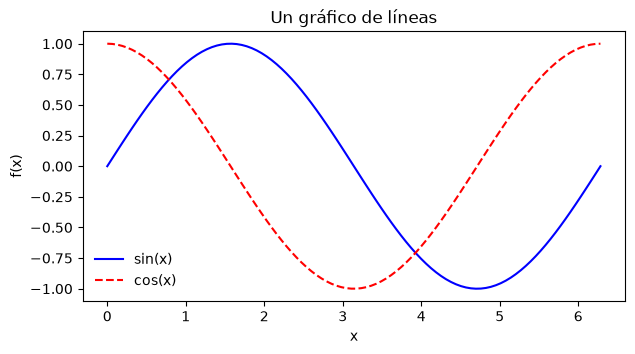

In [30]:
import matplotlib.pyplot as plt

x = np.linspace(0, 2 * np.pi, 100)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(x, np.sin(x), label="sin(x)", color="blue")
ax.plot(x, np.cos(x), label="cos(x)", color="red", linestyle="--")

ax.set_title("Un gráfico de líneas")
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.legend(frameon=False)
plt.show()

### 3.1 Los tres gráficos que más van a usar

`plt.subplots(filas, columnas)` crea una grilla de paneles, que indexamos como un array.

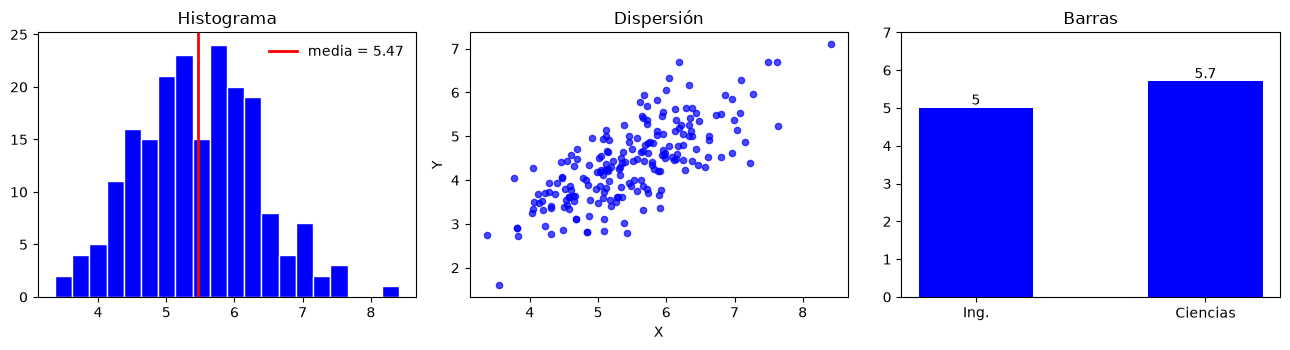

In [31]:
rng = np.random.default_rng(42)
datos = rng.normal(5.5, 1.0, 200)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

# Histograma: distribución de UNA variable numérica
axes[0].hist(datos, bins=20, color="blue", edgecolor="white")
axes[0].axvline(datos.mean(), color="red", lw=2, label=f"media = {datos.mean():.2f}")
axes[0].set_title("Histograma"); axes[0].legend(frameon=False)

# Dispersión: relación entre DOS variables
otra = 0.8 * datos + rng.normal(0, 0.6, 200)
axes[1].scatter(datos, otra, s=20, alpha=0.7, color="blue")
axes[1].set_title("Dispersión"); axes[1].set_xlabel("X"); axes[1].set_ylabel("Y")

# Barras: comparación entre categorías
barras = axes[2].bar(["Ing.", "Ciencias"], [5.0, 5.7], color="blue", width=0.5)
axes[2].bar_label(barras)     
axes[2].set_title("Barras"); axes[2].set_ylim(0, 7)

fig.tight_layout()
plt.show()

### 3.2 Graficar desde pandas y guardar la figura

Los `DataFrame` tienen un método `.plot()` que usa Matplotlib por debajo: es la vía
rápida mientras exploramos. `fig.savefig(...)` guarda en el formato de la extensión.

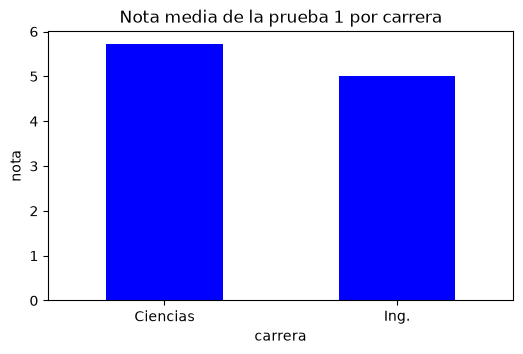

Figura guardada.


In [32]:
fig, ax = plt.subplots(figsize=(6, 3.5))
df.groupby("carrera")["prueba_1"].mean().plot(kind="bar", ax=ax, color="blue", rot=0)
ax.set_title("Nota media de la prueba 1 por carrera")
ax.set_ylabel("nota")
plt.show()

fig.savefig("results/notas_por_carrera.png")
print("Figura guardada.")